In [1]:
import pandas as pd
path = r"C:\Users\rober\OneDrive\Desktop\bank_showdown\complaints.csv"

In [2]:
import os
print(os.listdir(path))

['complaints.csv']


In [3]:
import pandas as pd

path = r"C:\Users\rober\OneDrive\Desktop\bank_showdown\complaints.csv\complaints.csv"

banks = ["CITIZENS FINANCIAL", "JPMORGAN", "BANK OF AMERICA", "WELLS FARGO",
         "CAPITAL ONE", "DISCOVER", "ALLY FINANCIAL", "PAYPAL", "BLOCK, INC", "CHIME"]
pattern = "|".join(banks)

cols = ["Date received", "Product", "Issue", "Company",
        "Company response to consumer", "Timely response?"]

pieces = []
for chunk in pd.read_csv(path, usecols=cols, parse_dates=["Date received"], chunksize=200_000):
    chunk = chunk[chunk["Date received"] >= "2021-01-01"]
    chunk = chunk[chunk["Company"].str.upper().str.contains(pattern, na=False)]
    pieces.append(chunk)

df = pd.concat(pieces)
df.to_csv("complaints_filtered.csv", index=False)

print(df.shape)
print(df["Company"].value_counts().head(20))

(615904, 6)
Company
CAPITAL ONE FINANCIAL CORPORATION        126371
JPMORGAN CHASE & CO.                     103861
WELLS FARGO & COMPANY                     93933
BANK OF AMERICA, NATIONAL ASSOCIATION     92405
Block, Inc.                               70932
Paypal Holdings, Inc                      34850
DISCOVER BANK                             30087
Chime Financial Inc                       29241
ALLY FINANCIAL INC.                       23055
CITIZENS FINANCIAL GROUP, INC.            10900
Chime Inc.                                  253
Discovery Auto Sales LLC                     16
Name: count, dtype: int64


In [4]:
df = df[df["Company"] != "Discovery Auto Sales LLC"].copy()

names = {
    "CAPITAL ONE FINANCIAL CORPORATION": "Capital One",
    "JPMORGAN CHASE & CO.": "Chase",
    "WELLS FARGO & COMPANY": "Wells Fargo",
    "BANK OF AMERICA, NATIONAL ASSOCIATION": "Bank of America",
    "Block, Inc.": "Block (Cash App)",
    "Paypal Holdings, Inc": "PayPal",
    "DISCOVER BANK": "Discover",
    "Chime Financial Inc": "Chime",
    "Chime Inc.": "Chime",
    "ALLY FINANCIAL INC.": "Ally",
    "CITIZENS FINANCIAL GROUP, INC.": "Citizens",
}
df["Bank"] = df["Company"].map(names)

groups = {
    "Chase": "Big Bank", "Bank of America": "Big Bank", "Wells Fargo": "Big Bank",
    "Capital One": "Big Bank", "Citizens": "Big Bank",
    "Ally": "Online Bank", "Discover": "Online Bank",
    "Block (Cash App)": "Fintech", "PayPal": "Fintech", "Chime": "Fintech",
}
df["Group"] = df["Bank"].map(groups)
df["Year"] = df["Date received"].dt.year

print("Unmatched banks:", df["Bank"].isna().sum())
print(df["Bank"].value_counts())
print(df["Date received"].min(), df["Date received"].max())
print(df["Company response to consumer"].value_counts())
print(df["Timely response?"].value_counts())

df.to_csv("complaints_clean.csv", index=False)

Unmatched banks: 0
Bank
Capital One         126371
Chase               103861
Wells Fargo          93933
Bank of America      92405
Block (Cash App)     70932
PayPal               34850
Discover             30087
Chime                29494
Ally                 23055
Citizens             10900
Name: count, dtype: int64
2021-01-01 00:00:00 2026-10-27 00:00:00
Company response to consumer
Closed with explanation            494812
Closed with non-monetary relief     60026
Closed with monetary relief         55549
In progress                          5490
Untimely response                      10
Name: count, dtype: int64
Timely response?
Yes    612021
No       3867
Name: count, dtype: int64


                  Complaints  Relief %  Monetary relief %  Timely %
Bank                                                               
PayPal                 34850     32.70              14.16     99.94
Bank of America        92405     31.94              24.59     96.97
Discover               30087     28.50               4.23    100.00
Wells Fargo            93933     20.30               8.17     99.99
Capital One           126371     18.52               5.37     99.99
Chase                 103861     17.31               8.14    100.00
Citizens               10900     15.88              15.88     99.98
Ally                   23055     10.43               3.39    100.00
Chime                  29494      8.45               5.92     99.77
Block (Cash App)       70932      0.17               0.17     98.65
Bank  Ally  Bank of America  Block (Cash App)  Capital One  Chase  Chime  \
Year                                                                       
2021  2232            11427     

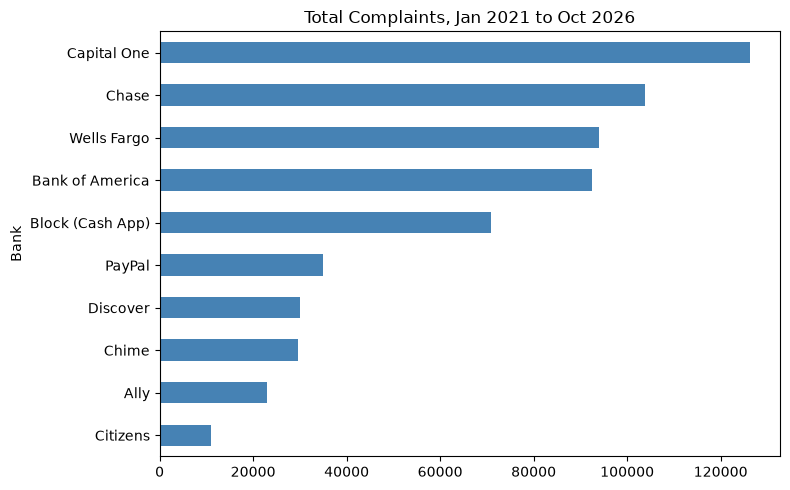

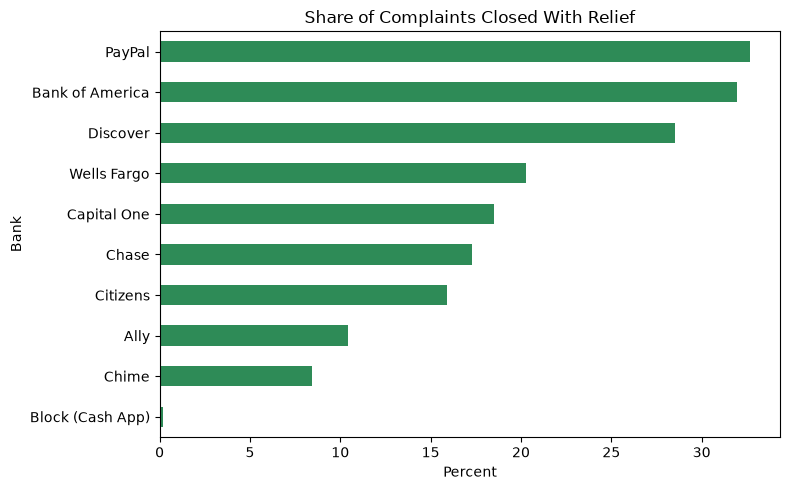

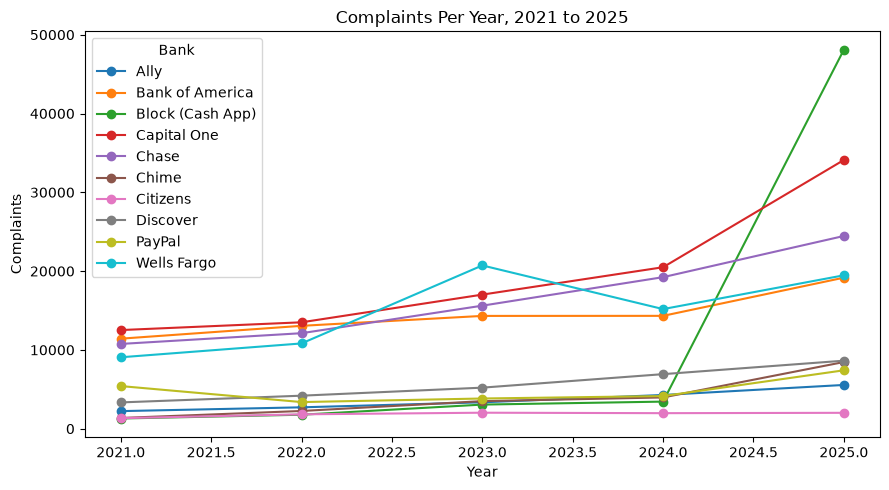

In [5]:
import matplotlib.pyplot as plt

closed = df[df["Company response to consumer"] != "In progress"]

summary = pd.DataFrame({
    "Complaints": df.groupby("Bank").size(),
    "Relief %": closed.groupby("Bank")["Company response to consumer"]
        .apply(lambda s: s.str.contains("relief").mean() * 100),
    "Monetary relief %": closed.groupby("Bank")["Company response to consumer"]
        .apply(lambda s: (s == "Closed with monetary relief").mean() * 100),
    "Timely %": df.groupby("Bank")["Timely response?"]
        .apply(lambda s: (s == "Yes").mean() * 100),
}).round(2).sort_values("Relief %", ascending=False)

print(summary)

yearly = df.groupby(["Year", "Bank"]).size().unstack().loc[2021:2025]
print(yearly)

summary.to_csv("summary_table.csv")

plt.figure(figsize=(8, 5))
summary["Complaints"].sort_values().plot(kind="barh", color="steelblue")
plt.title("Total Complaints, Jan 2021 to Oct 2026")
plt.tight_layout()
plt.savefig("chart_total_complaints.png", dpi=200)
plt.show()

plt.figure(figsize=(8, 5))
summary["Relief %"].sort_values().plot(kind="barh", color="seagreen")
plt.title("Share of Complaints Closed With Relief")
plt.xlabel("Percent")
plt.tight_layout()
plt.savefig("chart_relief_rate.png", dpi=200)
plt.show()

yearly.plot(figsize=(9, 5), marker="o")
plt.title("Complaints Per Year, 2021 to 2025")
plt.ylabel("Complaints")
plt.tight_layout()
plt.savefig("chart_yearly_trend.png", dpi=200)
plt.show()

In [6]:
print(pd.crosstab(df["Product"], df["Bank"]))

b = df[(df["Bank"] == "Block (Cash App)") & (df["Year"] == 2025)]
print(b["Issue"].value_counts().head(8))
print(b["Date received"].dt.to_period("M").value_counts().sort_index())

Bank                                                Ally  Bank of America  \
Product                                                                     
Checking or savings account                         3887            34620   
Credit card                                          467            13902   
Credit card or prepaid card                          189             9137   
Credit reporting or other personal consumer rep...  6842            11961   
Credit reporting, credit repair services, or ot...  2760             4884   
Debt collection                                     2034             4999   
Debt or credit management                             25              100   
Money transfer, virtual currency, or money service   374             6348   
Mortgage                                             193             3795   
Payday loan, title loan, or personal loan            106              167   
Payday loan, title loan, personal loan, or adva...    76              136   

In [7]:
core_products = ["Checking or savings account", "Credit card",
                 "Credit card or prepaid card", "Prepaid card"]
money_products = ["Money transfer, virtual currency, or money service"]

core = df[df["Product"].isin(core_products)].copy()
money = df[df["Product"].isin(money_products)].copy()

def scoreboard(d):
    closed = d[d["Company response to consumer"] != "In progress"]
    resp = closed["Company response to consumer"]
    return pd.DataFrame({
        "Complaints": d.groupby("Bank").size(),
        "Relief %": resp.groupby(closed["Bank"]).apply(lambda s: s.str.contains("relief").mean() * 100),
        "Monetary relief %": resp.groupby(closed["Bank"]).apply(lambda s: (s == "Closed with monetary relief").mean() * 100),
    }).round(2).sort_values("Relief %", ascending=False)

print("CORE BANKING")
print(scoreboard(core))

print("MONEY TRANSFER")
print(scoreboard(money))

spike = (money["Bank"] == "Block (Cash App)") & (money["Date received"] >= "2025-01-01") & (money["Date received"] < "2025-02-01")
print("MONEY TRANSFER, WITHOUT BLOCK'S JAN 2025 SPIKE")
print(scoreboard(money[~spike]))

print(core.groupby(["Year", "Bank"]).size().unstack().loc[2021:2025])

core.to_csv("complaints_core.csv", index=False)
money.to_csv("complaints_money.csv", index=False)

CORE BANKING
                  Complaints  Relief %  Monetary relief %
Bank                                                     
Bank of America        58952     40.93              34.53
PayPal                  6272     34.95              18.23
Ally                    4544     29.43              10.54
Discover               12810     25.78               8.67
Citizens                5995     24.97              24.97
Capital One            62322     19.87              10.36
Wells Fargo            52744     19.79              12.40
Chase                  65555     18.71              11.79
Chime                  23584      8.71               6.35
Block (Cash App)       13215      0.24               0.24
MONEY TRANSFER
                  Complaints  Relief %  Monetary relief %
Bank                                                     
PayPal                 26838     31.52              13.30
Ally                     374     26.76              17.30
Discover                 332     23.19      

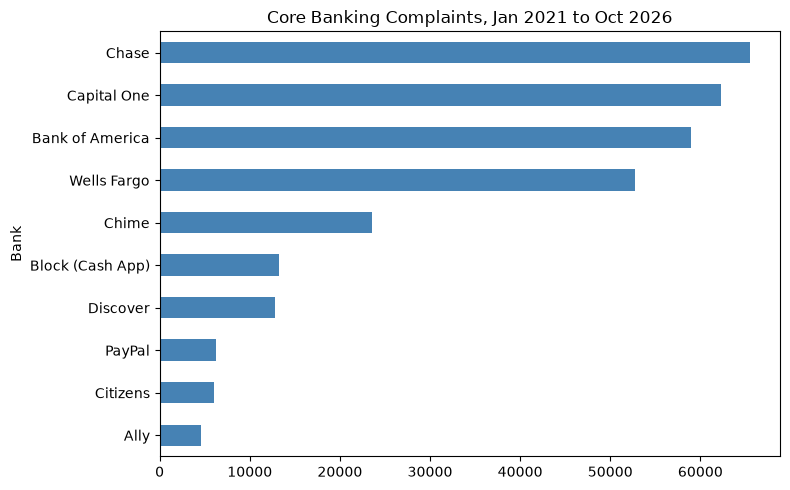

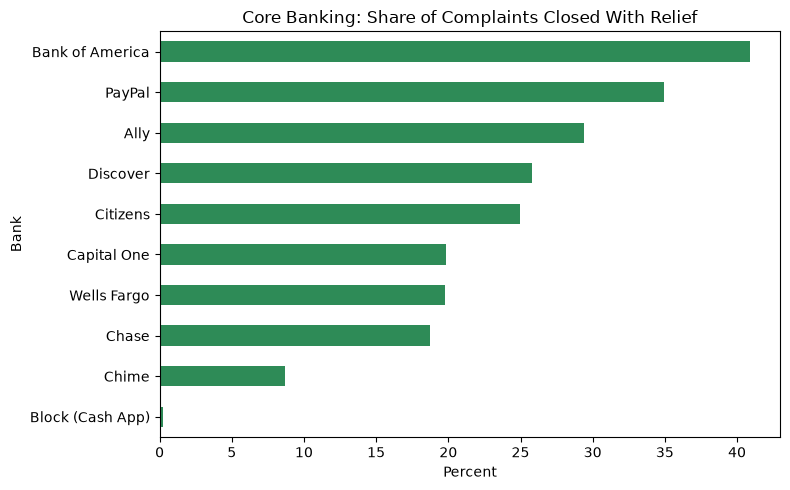

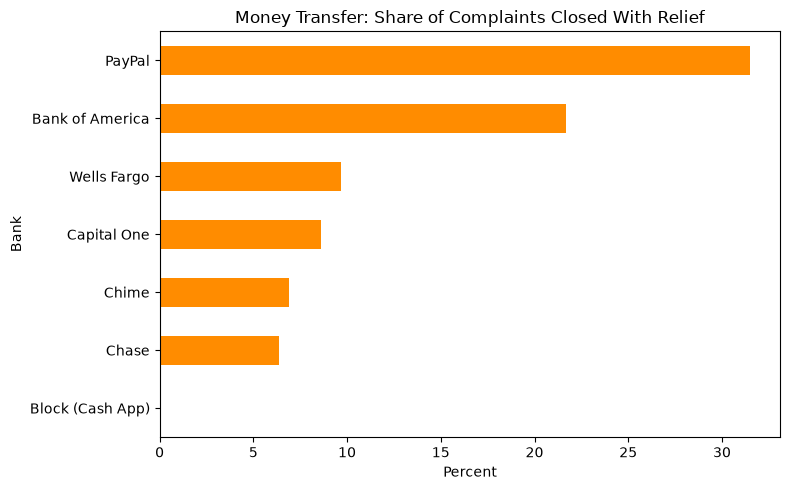

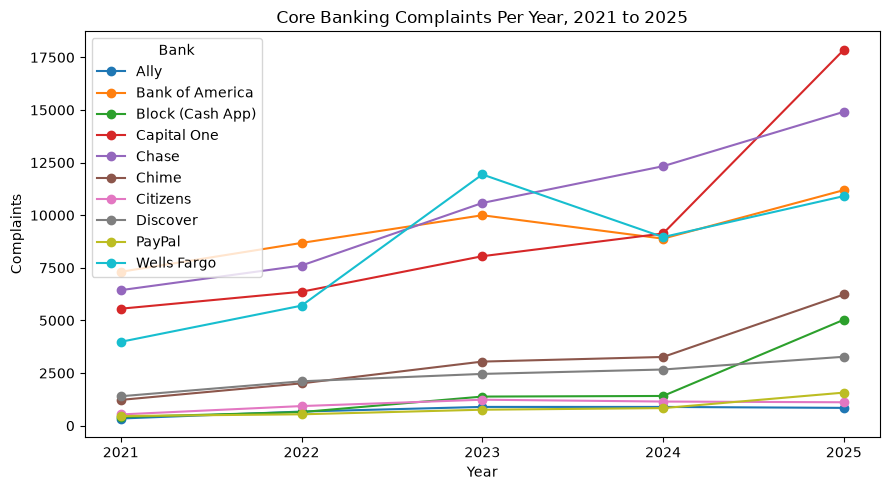

In [8]:
import matplotlib.pyplot as plt

core_sum = scoreboard(core)
money_sum = scoreboard(money)
money_sum = money_sum[money_sum["Complaints"] >= 1000]

core_sum["Complaints"].sort_values().plot(kind="barh", color="steelblue", figsize=(8, 5))
plt.title("Core Banking Complaints, Jan 2021 to Oct 2026")
plt.tight_layout()
plt.savefig("chart_total_complaints.png", dpi=200)
plt.show()

core_sum["Relief %"].sort_values().plot(kind="barh", color="seagreen", figsize=(8, 5))
plt.title("Core Banking: Share of Complaints Closed With Relief")
plt.xlabel("Percent")
plt.tight_layout()
plt.savefig("chart_relief_rate.png", dpi=200)
plt.show()

money_sum["Relief %"].sort_values().plot(kind="barh", color="darkorange", figsize=(8, 5))
plt.title("Money Transfer: Share of Complaints Closed With Relief")
plt.xlabel("Percent")
plt.tight_layout()
plt.savefig("chart_money_transfer_relief.png", dpi=200)
plt.show()

yearly = core.groupby(["Year", "Bank"]).size().unstack().loc[2021:2025]
yearly.plot(figsize=(9, 5), marker="o")
plt.xticks(range(2021, 2026))
plt.title("Core Banking Complaints Per Year, 2021 to 2025")
plt.ylabel("Complaints")
plt.tight_layout()
plt.savefig("chart_yearly_trend.png", dpi=200)
plt.show()

core_sum["Group"] = "Core banking"
money_sum["Group"] = "Money transfer"
pd.concat([core_sum, money_sum]).to_csv("summary_table.csv")

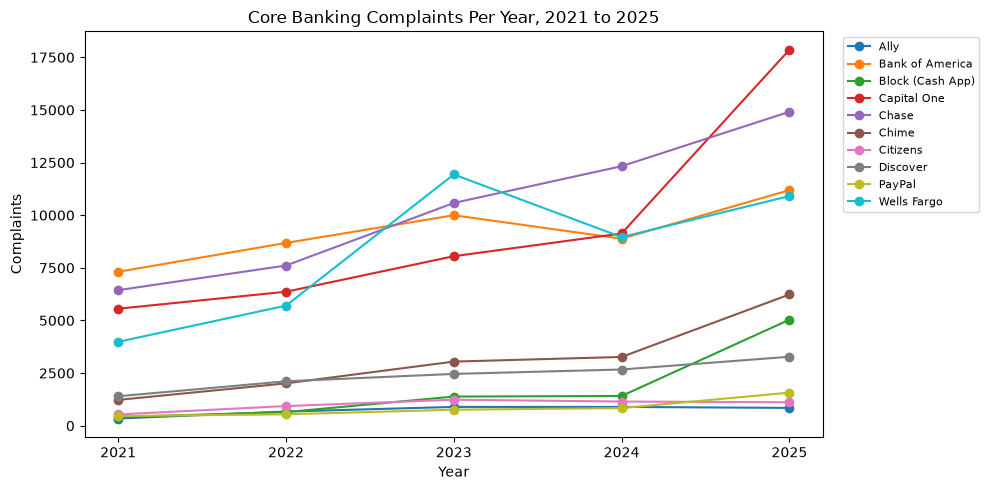

In [9]:
yearly = core.groupby(["Year", "Bank"]).size().unstack().loc[2021:2025]
yearly.plot(figsize=(10, 5), marker="o")
plt.xticks(range(2021, 2026))
plt.title("Core Banking Complaints Per Year, 2021 to 2025")
plt.ylabel("Complaints")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("chart_yearly_trend.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
b = df[(df["Bank"] == "Block (Cash App)") & (df["Date received"] >= "2025-01-01") & (df["Date received"] < "2025-02-01")]
print(b.groupby(b["Date received"].dt.date).size())
print(b["Issue"].value_counts().head(5))

Date received
2025-01-01        4
2025-01-02       20
2025-01-03       14
2025-01-04       12
2025-01-05        8
2025-01-06       18
2025-01-07       14
2025-01-08       12
2025-01-09       16
2025-01-10       14
2025-01-11       11
2025-01-12        9
2025-01-13       14
2025-01-14       14
2025-01-15       27
2025-01-16     1448
2025-01-17    12793
2025-01-18     5768
2025-01-19     1869
2025-01-20     3527
2025-01-21     1462
2025-01-22      711
2025-01-23      649
2025-01-24      444
2025-01-25      246
2025-01-26      236
2025-01-27      262
2025-01-28      312
2025-01-29      453
2025-01-30      508
2025-01-31      432
dtype: int64
Issue
Other transaction problem                                 27659
Fraud or scam                                               817
Other service problem                                       756
Unauthorized transactions or other transaction problem      679
Managing an account                                         279
Name: count, dtype: int64


In [11]:
deposits_thousands = {   # FDIC BankFind, domestic deposits at 06/30/2024, in $ thousands
    "Chase": 2_008_751_000,
    "Bank of America": 1_901_768_650,
    "Wells Fargo": 1_403_197_000,
    "Capital One": 372_464_078,
    "Ally": 155_556_000,
    "Citizens": 180_066_467,
    "Discover": 112_081_206,
}
chk = core[(core["Product"] == "Checking or savings account") & (core["Year"] == 2024)]
norm = pd.DataFrame({"Complaints": chk.groupby("Bank").size(),
                     "Deposits $B": pd.Series(deposits_thousands, dtype=float) / 1_000_000}).dropna()
norm["Per $1B deposits"] = (norm["Complaints"] / norm["Deposits $B"]).round(2)
print(norm.sort_values("Per $1B deposits"))

                 Complaints  Deposits $B  Per $1B deposits
Bank of America        4996  1901.768650              2.63
Discover                363   112.081206              3.24
Chase                  7036  2008.751000              3.50
Ally                    666   155.556000              4.28
Wells Fargo            6805  1403.197000              4.85
Citizens                991   180.066467              5.50
Capital One            2064   372.464078              5.54


                 Complaints  Deposits $B  Per $1B deposits  Relief %
Bank of America        4996  1901.768650              2.63      46.8
Discover                363   112.081206              3.24      36.4
Chase                  7036  2008.751000              3.50      15.3
Ally                    666   155.556000              4.28      36.2
Wells Fargo            6805  1403.197000              4.85      17.9
Citizens                991   180.066467              5.50      26.2
Capital One            2064   372.464078              5.54      20.4


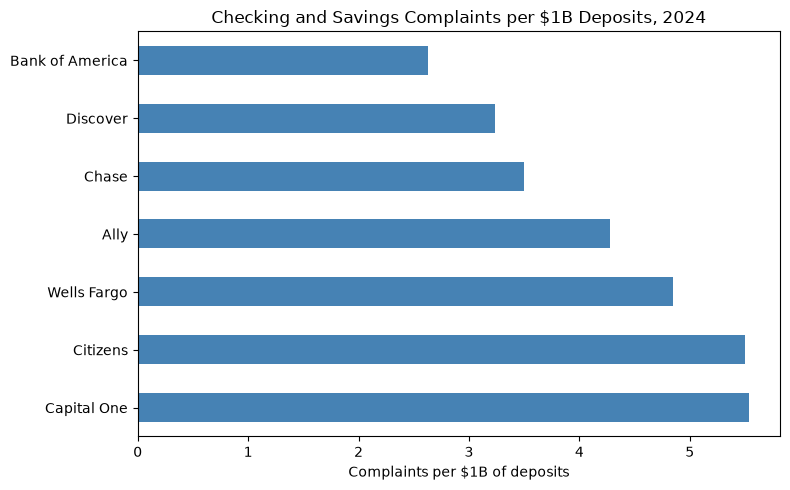

In [12]:
chk_closed = chk[chk["Company response to consumer"] != "In progress"]
norm["Relief %"] = chk_closed.groupby("Bank")["Company response to consumer"] \
    .apply(lambda s: s.str.contains("relief").mean() * 100).round(1)
print(norm.sort_values("Per $1B deposits"))

norm["Per $1B deposits"].sort_values(ascending=False).plot(kind="barh", color="steelblue", figsize=(8, 5))
plt.title("Checking and Savings Complaints per $1B Deposits, 2024")
plt.xlabel("Complaints per $1B of deposits")
plt.tight_layout()
plt.savefig("chart_complaints_per_deposit.png", dpi=200)
plt.show()

In [13]:
   norm.to_csv("summary_checking_per_deposit.csv")

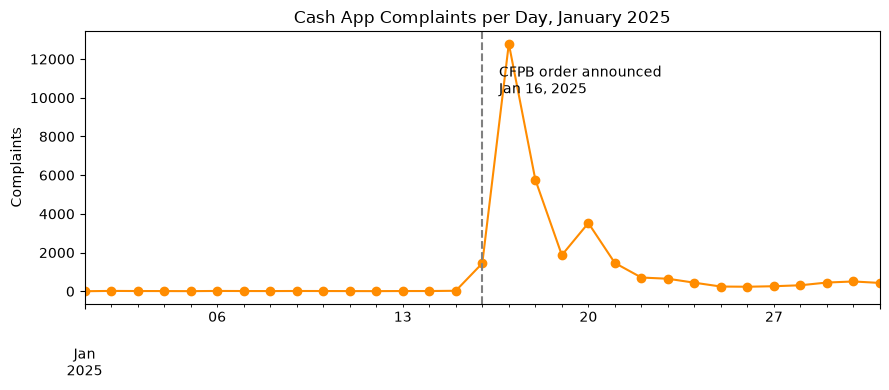

In [14]:
daily = b.groupby(b["Date received"].dt.normalize()).size()
ax = daily.plot(marker="o", figsize=(9, 4), color="darkorange")
ax.axvline(pd.Timestamp("2025-01-16"), linestyle="--", color="gray")
ax.annotate("CFPB order announced\nJan 16, 2025", xy=(pd.Timestamp("2025-01-16"), daily.max() * 0.8),
            xytext=(12, 0), textcoords="offset points")
ax.set_title("Cash App Complaints per Day, January 2025")
ax.set_xlabel("")
ax.set_ylabel("Complaints")
plt.tight_layout()
plt.savefig("chart_cashapp_jan2025.png", dpi=200)
plt.show()

In [15]:
pp = int((fin["Bank"] == "PayPal").sum())            # PayPal 2024 complaints
cash_rate = ft.loc["Block (Cash App)", "Per 1M actives"]
chime_rate = ft.loc["Chime", "Per 1M actives"]

print("PayPal 2024 complaints:", pp)
for share in [0.25, 0.35, 0.45, 0.575, 1.0]:
    us_m = 434 * share
    print(f"If {share:.0%} of accounts are US ({us_m:.0f}M): {pp / us_m:.1f} per 1M")
print()
print(f"PayPal matches Cash App ({cash_rate}) at {pp / cash_rate:.0f}M US accounts")
print(f"PayPal matches Chime ({chime_rate}) at {pp / chime_rate:.0f}M US accounts")

NameError: name 'fin' is not defined

                  Complaints  Actives (M)  Per 1M actives  Relief %
PayPal                  4143        434.0             9.5      27.1
Block (Cash App)        3439         57.0            60.3       0.8
Chime                   3970          8.0           496.2      11.7


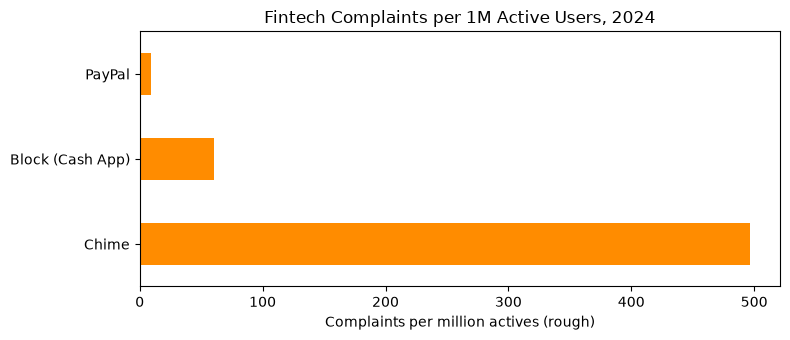


PayPal 2024 complaints: 4143
If 25% of accounts are US (108M): 38.2 per 1M
If 35% of accounts are US (152M): 27.3 per 1M
If 45% of accounts are US (195M): 21.2 per 1M
If 57% of accounts are US (250M): 16.6 per 1M
If 100% of accounts are US (434M): 9.5 per 1M

PayPal matches Cash App (60.3) at 69M US accounts
PayPal matches Chime (496.2) at 8M US accounts


In [16]:
actives_m = {"Chime": 8.0, "Block (Cash App)": 57.0, "PayPal": 434.0}   # millions, Dec 2024
fin = df[(df["Year"] == 2024) & (df["Bank"].isin(actives_m))]
fin_closed = fin[fin["Company response to consumer"] != "In progress"]

ft = pd.DataFrame({"Complaints": fin.groupby("Bank").size(),
                   "Actives (M)": pd.Series(actives_m)})
ft["Per 1M actives"] = (ft["Complaints"] / ft["Actives (M)"]).round(1)
ft["Relief %"] = fin_closed.groupby("Bank")["Company response to consumer"] \
    .apply(lambda s: s.str.contains("relief").mean() * 100).round(1)
print(ft.sort_values("Per 1M actives"))

ft["Per 1M actives"].sort_values(ascending=False).plot(kind="barh", color="darkorange", figsize=(8, 3.5))
plt.title("Fintech Complaints per 1M Active Users, 2024")
plt.xlabel("Complaints per million actives (rough)")
plt.tight_layout()
plt.savefig("chart_fintech_per_user.png", dpi=200)
plt.show()
ft.to_csv("summary_fintech_per_user.csv")

print()
pp = int(ft.loc["PayPal", "Complaints"])
cash_rate = ft.loc["Block (Cash App)", "Per 1M actives"]
chime_rate = ft.loc["Chime", "Per 1M actives"]
print("PayPal 2024 complaints:", pp)
for share in [0.25, 0.35, 0.45, 0.575, 1.0]:
    us_m = 434 * share
    print(f"If {share:.0%} of accounts are US ({us_m:.0f}M): {pp / us_m:.1f} per 1M")
print()
print(f"PayPal matches Cash App ({cash_rate}) at {pp / cash_rate:.0f}M US accounts")
print(f"PayPal matches Chime ({chime_rate}) at {pp / chime_rate:.0f}M US accounts")

In [17]:
pp = int((fin["Bank"] == "PayPal").sum())            # PayPal 2024 complaints
cash_rate = ft.loc["Block (Cash App)", "Per 1M actives"]
chime_rate = ft.loc["Chime", "Per 1M actives"]

print("PayPal 2024 complaints:", pp)
for share in [0.25, 0.35, 0.45, 0.575, 1.0]:
    us_m = 434 * share
    print(f"If {share:.0%} of accounts are US ({us_m:.0f}M): {pp / us_m:.1f} per 1M")
print()
print(f"PayPal matches Cash App ({cash_rate}) at {pp / cash_rate:.0f}M US accounts")
print(f"PayPal matches Chime ({chime_rate}) at {pp / chime_rate:.0f}M US accounts")

PayPal 2024 complaints: 4143
If 25% of accounts are US (108M): 38.2 per 1M
If 35% of accounts are US (152M): 27.3 per 1M
If 45% of accounts are US (195M): 21.2 per 1M
If 57% of accounts are US (250M): 16.6 per 1M
If 100% of accounts are US (434M): 9.5 per 1M

PayPal matches Cash App (60.3) at 69M US accounts
PayPal matches Chime (496.2) at 8M US accounts
